In [ ]:
import pandas as pd
import numpy as np

file_path = r"C:\AI-Anomaly-Detection\outputs\dataset_feature_engineering.csv"

df = pd.read_csv(file_path)

print("Jumlah baris:", len(df))
print("Jumlah kolom:", len(df.columns))
print("Jumlah sesi:", df["session_id"].nunique())

Dataset berhasil dimuat!
Jumlah baris: 38531
Jumlah kolom: 24
Jumlah sesi: 52


,id_monitoring_udara,suhu,kelembaban,pm10,pm25,barometer,tvoc,waktu_tercatat,gap_sec,session_id,...,barometer_change_flag,barometer_delta,pm10_duration,pm10_change_flag,pm10_delta,pm25_duration,pm25_change_flag,pm25_delta,gap_panjang_flag,awal_sesi_flag
0,164460,29.39,46,8.0,3.0,701.29,740.63,2026-01-19 11:40:18,NaN,1,...,1,0.00,0.0,1,0.0,0.0,1,0.0,0,1
1,164461,29.29,46,5.0,2.0,701.27,740.63,2026-01-19 11:41:22,64.0,1,...,1,-0.02,0.0,1,-3.0,0.0,1,-1.0,0,0
2,164462,29.39,45,1.0,0.0,701.26,740.63,2026-01-19 11:42:27,65.0,1,...,1,-0.01,0.0,1,-4.0,0.0,1,-2.0,0,0
3,164463,29.39,45,4.0,1.0,701.26,740.63,2026-01-19 11:43:31,64.0,1,...,0,0.00,0.0,1,3.0,0.0,1,1.0,0,0
4,164464,29.29,44,0.0,0.0,701.27,740.63,2026-01-19 11:44:36,65.0,1,...,1,0.01,0.0,1,-4.0,0.0,1,-1.0,0,0


In [2]:
print("DAFTAR SELURUH KOLOM DATASET:\n")

for i, kolom in enumerate(df.columns, start=1):
    print(f"{i}. {kolom}")

print("\nJumlah kolom:", len(df.columns))

DAFTAR SELURUH KOLOM DATASET:

1. id_monitoring_udara
2. suhu
3. kelembaban
4. pm10
5. pm25
6. barometer
7. tvoc
8. waktu_tercatat
9. gap_sec
10. session_id
11. tvoc_duration
12. tvoc_change_flag
13. tvoc_delta
14. barometer_duration
15. barometer_change_flag
16. barometer_delta
17. pm10_duration
18. pm10_change_flag
19. pm10_delta
20. pm25_duration
21. pm25_change_flag
22. pm25_delta
23. gap_panjang_flag
24. awal_sesi_flag

Jumlah kolom: 24


In [3]:
fitur_sensor = [
    "suhu",
    "kelembaban",
    "pm10",
    "pm25",
    "barometer",
    "tvoc"
]

fitur_temporal = [
    "tvoc_duration",
    "tvoc_change_flag",
    "tvoc_delta",
    "barometer_duration",
    "barometer_change_flag",
    "barometer_delta",
    "pm10_duration",
    "pm10_change_flag",
    "pm10_delta",
    "pm25_duration",
    "pm25_change_flag",
    "pm25_delta",
    "gap_panjang_flag",
    "awal_sesi_flag"
]

fitur_identitas = [
    "id_monitoring_udara",
    "waktu_tercatat",
    "gap_sec",
    "session_id"
]

print("Jumlah fitur sensor:", len(fitur_sensor))
print("Jumlah fitur temporal:", len(fitur_temporal))
print("Jumlah fitur identitas:", len(fitur_identitas))
print("Total:", len(fitur_sensor) + len(fitur_temporal) + len(fitur_identitas))

Jumlah fitur sensor: 6
Jumlah fitur temporal: 14
Jumlah fitur identitas: 4
Total: 24


In [4]:
fitur_model = fitur_sensor + fitur_temporal

print("Jumlah fitur kandidat:", len(fitur_model))

print("\nPemeriksaan nilai kosong:")
display(df[fitur_model].isna().sum())

print("\nTotal nilai kosong:",
      df[fitur_model].isna().sum().sum())

print("\nTotal nilai tak terhingga:",
      np.isinf(df[fitur_model]).sum().sum())

Jumlah fitur kandidat: 20

Pemeriksaan nilai kosong:


suhu                     0
kelembaban               0
pm10                     0
pm25                     0
barometer                0
tvoc                     0
tvoc_duration            0
tvoc_change_flag         0
tvoc_delta               0
barometer_duration       0
barometer_change_flag    0
barometer_delta          0
pm10_duration            0
pm10_change_flag         0
pm10_delta               0
pm25_duration            0
pm25_change_flag         0
pm25_delta               0
gap_panjang_flag         0
awal_sesi_flag           0
dtype: int64


Total nilai kosong: 0

Total nilai tak terhingga: 0


In [5]:
display(
    df[fitur_model]
    .describe()
    .T
    .round(3)
)

,count,mean,std,min,25%,50%,75%,max
suhu,38531.0,27.293,4.963,13.80,23.930,26.220,30.090,44.780
kelembaban,38531.0,57.958,12.579,21.00,49.000,61.000,68.000,79.000
pm10,38531.0,33.058,15.975,0.00,20.000,32.000,44.000,489.000
pm25,38531.0,15.832,7.411,0.00,11.000,16.000,21.000,221.000
barometer,38531.0,705.860,19.702,650.43,700.090,702.020,703.710,758.110
tvoc,38531.0,687.484,230.910,83.45,713.870,731.700,749.560,1366.630
tvoc_duration,38531.0,66.224,64.057,0.00,19.183,47.283,93.025,429.750
tvoc_change_flag,38531.0,0.029,0.167,0.00,0.000,0.000,0.000,1.000
tvoc_delta,38531.0,0.000,1.466,-9.49,0.000,0.000,0.000,9.490
barometer_duration,38531.0,0.252,0.624,0.00,0.000,0.000,0.000,7.867


In [6]:
kolom_sensor = [
    "suhu",
    "kelembaban",
    "pm10",
    "pm25",
    "barometer",
    "tvoc"
]

hasil_iqr = []

for sensor in kolom_sensor:
    Q1 = df[sensor].quantile(0.25)
    Q3 = df[sensor].quantile(0.75)

    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    jumlah_ekstrem = (
        (df[sensor] < batas_bawah) |
        (df[sensor] > batas_atas)
    ).sum()

    hasil_iqr.append({
        "sensor": sensor,
        "batas_bawah": round(batas_bawah, 2),
        "batas_atas": round(batas_atas, 2),
        "jumlah_nilai_ekstrem": jumlah_ekstrem
    })

hasil_iqr = pd.DataFrame(hasil_iqr)

display(hasil_iqr)

,sensor,batas_bawah,batas_atas,jumlah_nilai_ekstrem
0,suhu,14.69,39.33,1023
1,kelembaban,20.50,96.50,0
2,pm10,-16.00,80.00,148
3,pm25,-4.00,36.00,300
4,barometer,694.66,709.14,7072
5,tvoc,660.34,803.09,7599


In [7]:
sensor_periksa = ["barometer", "tvoc"]

for sensor in sensor_periksa:
    Q1 = df[sensor].quantile(0.25)
    Q3 = df[sensor].quantile(0.75)
    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    data_ekstrem = df[
        (df[sensor] < batas_bawah) |
        (df[sensor] > batas_atas)
    ]

    print(f"\nContoh nilai ekstrem {sensor}:")
    display(
        data_ekstrem[
            ["session_id", "waktu_tercatat", sensor, f"{sensor}_delta"]
        ].head(10)
    )


Contoh nilai ekstrem barometer:


,session_id,waktu_tercatat,barometer,barometer_delta
11384,12,2026-05-11 10:33:22,755.35,0.00
11385,12,2026-05-11 10:34:25,755.34,-0.01
11386,12,2026-05-11 10:35:28,755.33,-0.01
11387,12,2026-05-11 10:36:31,755.32,-0.01
11388,12,2026-05-11 10:37:34,755.33,0.01
11389,12,2026-05-11 10:38:37,755.30,-0.03
11390,12,2026-05-11 10:39:40,755.25,-0.05
11391,13,2026-05-11 11:40:35,754.55,0.00
11392,13,2026-05-11 11:41:38,754.52,-0.03
11393,13,2026-05-11 11:42:42,754.51,-0.01



Contoh nilai ekstrem tvoc:


,session_id,waktu_tercatat,tvoc,tvoc_delta
4857,6,2026-04-13 14:32:52,803.32,8.98
4858,6,2026-04-13 14:33:55,803.32,0.00
4859,6,2026-04-13 14:34:58,803.32,0.00
4860,6,2026-04-13 14:37:18,803.32,0.00
4861,6,2026-04-13 14:38:21,803.32,0.00
4862,6,2026-04-13 14:39:25,803.32,0.00
4863,6,2026-04-13 14:40:28,803.32,0.00
4864,6,2026-04-13 14:41:31,803.32,0.00
4865,6,2026-04-13 14:42:34,803.32,0.00
4866,6,2026-04-13 14:43:37,803.32,0.00


In [8]:
sensor_periksa = ["barometer", "tvoc"]

for sensor in sensor_periksa:
    Q1 = df[sensor].quantile(0.25)
    Q3 = df[sensor].quantile(0.75)
    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    kondisi = (
        (df[sensor] < batas_bawah) |
        (df[sensor] > batas_atas)
    )

    ringkasan = (
        df[kondisi]
        .groupby("session_id")
        .agg(
            jumlah_nilai_ekstrem=(sensor, "count"),
            nilai_minimum=(sensor, "min"),
            nilai_maksimum=(sensor, "max")
        )
        .reset_index()
    )

    print(f"\nDistribusi nilai ekstrem {sensor}:")
    display(ringkasan)


Distribusi nilai ekstrem barometer:


,session_id,jumlah_nilai_ekstrem,nilai_minimum,nilai_maksimum
0,12,7,755.25,755.35
1,13,1011,752.61,756.10
2,15,1155,748.91,752.61
3,16,247,693.83,694.66
4,19,1075,690.85,692.92
5,20,7,692.27,692.34
6,27,1217,650.43,652.89
7,48,1115,754.22,758.11
8,50,1238,750.57,754.88



Distribusi nilai ekstrem tvoc:


,session_id,jumlah_nilai_ekstrem,nilai_minimum,nilai_maksimum
0,6,10,803.32,803.32
1,12,7,117.01,117.01
2,13,1011,108.61,142.26
3,15,1155,142.26,184.48
4,16,764,803.32,830.31
5,19,1075,839.32,866.40
6,20,7,848.34,848.34
7,27,1217,1328.72,1366.63
8,48,1115,83.45,125.42
9,50,1238,117.01,167.57


In [9]:
ringkasan_sesi = (
    df.groupby("session_id")
    .agg(
        jumlah_data=("barometer", "count"),
        barometer_mean=("barometer", "mean"),
        barometer_std=("barometer", "std"),
        tvoc_mean=("tvoc", "mean"),
        tvoc_std=("tvoc", "std")
    )
    .round(3)
    .reset_index()
)

display(ringkasan_sesi)

,session_id,jumlah_data,barometer_mean,barometer_std,tvoc_mean,tvoc_std
0,1,1136,701.514,1.000,736.138,12.181
1,2,1289,703.273,0.812,715.685,9.130
2,3,282,698.260,0.750,775.710,9.652
3,4,746,700.042,0.641,753.937,8.416
4,5,1211,701.518,0.786,736.304,9.857
5,6,1191,698.136,0.885,776.688,10.885
6,7,1065,701.450,1.114,737.449,13.091
7,8,1046,700.440,0.976,748.858,11.751
8,9,1143,699.045,1.008,765.811,12.218
9,10,1144,702.415,0.877,726.099,10.519


In [10]:
kolom_sensor = [
    "barometer",
    "tvoc"
]

for sensor in kolom_sensor:
    rata_sesi = df.groupby("session_id")[sensor].transform("mean")
    std_sesi = df.groupby("session_id")[sensor].transform("std")

    df[f"{sensor}_deviasi_sesi"] = df[sensor] - rata_sesi

    df[f"{sensor}_zscore_sesi"] = (
        df[f"{sensor}_deviasi_sesi"] / std_sesi.replace(0, np.nan)
    )

display(
    df[
        [
            "session_id",
            "barometer",
            "barometer_zscore_sesi",
            "tvoc",
            "tvoc_zscore_sesi"
        ]
    ].head(15).round(3)
)

,session_id,barometer,barometer_zscore_sesi,tvoc,tvoc_zscore_sesi
0,1,701.29,-0.224,740.63,0.369
1,1,701.27,-0.244,740.63,0.369
2,1,701.26,-0.254,740.63,0.369
3,1,701.26,-0.254,740.63,0.369
4,1,701.27,-0.244,740.63,0.369
5,1,701.26,-0.254,740.63,0.369
6,1,701.26,-0.254,740.63,0.369
7,1,701.25,-0.264,740.63,0.369
8,1,701.26,-0.254,740.63,0.369
9,1,701.26,-0.254,740.63,0.369


In [11]:
kolom_zscore = [
    "barometer_zscore_sesi",
    "tvoc_zscore_sesi"
]

for kolom in kolom_zscore:
    jumlah_ekstrem = (
        df[kolom].abs() > 3
    ).sum()

    persentase = jumlah_ekstrem / len(df) * 100

    print(f"\n{kolom}")
    print("Jumlah nilai ekstrem:", jumlah_ekstrem)
    print("Persentase:", round(persentase, 3), "%")


barometer_zscore_sesi
Jumlah nilai ekstrem: 2
Persentase: 0.005 %

tvoc_zscore_sesi
Jumlah nilai ekstrem: 3
Persentase: 0.008 %


In [12]:
data_zscore_ekstrem = df[
    (df["barometer_zscore_sesi"].abs() > 3) |
    (df["tvoc_zscore_sesi"].abs() > 3)
]

display(
    data_zscore_ekstrem[
        [
            "session_id",
            "waktu_tercatat",
            "barometer",
            "barometer_zscore_sesi",
            "tvoc",
            "tvoc_zscore_sesi"
        ]
    ].round(3)
)

,session_id,waktu_tercatat,barometer,barometer_zscore_sesi,tvoc,tvoc_zscore_sesi
21202,24,2026-06-18 12:20:19,701.93,-3.402,731.70,2.948
21203,24,2026-06-18 12:22:40,701.94,-3.362,731.70,2.948
24738,30,2026-07-23 09:57:55,704.53,-1.650,704.97,7.072
24864,34,2026-07-27 12:53:58,701.91,2.865,731.70,-3.090
24865,34,2026-07-27 12:57:36,701.90,2.816,731.70,-3.090


In [13]:
fitur_temporal_utama = [
    "tvoc_duration",
    "barometer_duration",
    "pm10_duration",
    "pm25_duration",
    "tvoc_delta",
    "barometer_delta",
    "pm10_delta",
    "pm25_delta"
]

display(
    df[fitur_temporal_utama]
    .describe()
    .T
    .round(3)
)

,count,mean,std,min,25%,50%,75%,max
tvoc_duration,38531.0,66.224,64.057,0.00,19.183,47.283,93.025,429.750
barometer_duration,38531.0,0.252,0.624,0.00,0.000,0.000,0.000,7.867
pm10_duration,38531.0,0.243,0.865,0.00,0.000,0.000,0.000,30.667
pm25_duration,38531.0,0.745,1.584,0.00,0.000,0.000,1.050,32.233
tvoc_delta,38531.0,0.000,1.466,-9.49,0.000,0.000,0.000,9.490
barometer_delta,38531.0,-0.000,0.028,-0.61,-0.020,0.000,0.020,0.560
pm10_delta,38531.0,0.003,6.493,-454.00,-2.000,0.000,2.000,470.000
pm25_delta,38531.0,0.001,3.108,-204.00,-1.000,0.000,1.000,211.000


In [14]:
kolom_delta = [
    "tvoc_delta",
    "barometer_delta",
    "pm10_delta",
    "pm25_delta"
]

for kolom in kolom_delta:
    print(f"\nNilai ekstrem {kolom}:")

    display(
        df.loc[
            df[kolom].abs().nlargest(5).index,
            [
                "session_id",
                "waktu_tercatat",
                kolom
            ]
        ]
    )


Nilai ekstrem tvoc_delta:


,session_id,waktu_tercatat,tvoc_delta
23569,27,2026-06-26 14:14:28,9.49
23573,27,2026-06-26 14:18:41,-9.49
23575,27,2026-06-26 14:20:47,9.49
23615,27,2026-06-26 15:02:59,-9.49
23622,27,2026-06-26 15:10:23,9.49



Nilai ekstrem barometer_delta:


,session_id,waktu_tercatat,barometer_delta
51,1,2026-01-19 13:30:22,-0.61
37418,50,2026-11-12 18:27:24,0.56
21202,24,2026-06-18 12:20:19,-0.52
24866,34,2026-07-27 13:45:17,-0.52
21206,25,2026-06-18 13:58:40,-0.34



Nilai ekstrem pm10_delta:


,session_id,waktu_tercatat,pm10_delta
20028,23,2026-06-15 13:17:41,470.0
20029,23,2026-06-15 13:18:44,-454.0
19914,23,2026-06-15 11:09:57,-317.0
19913,23,2026-06-15 11:08:54,304.0
25734,40,2026-08-29 01:32:46,165.0



Nilai ekstrem pm25_delta:


,session_id,waktu_tercatat,pm25_delta
20028,23,2026-06-15 13:17:41,211.0
20029,23,2026-06-15 13:18:44,-204.0
19914,23,2026-06-15 11:09:57,-157.0
19913,23,2026-06-15 11:08:54,151.0
25734,40,2026-08-29 01:32:46,85.0


In [15]:
indeks_periksa = [19913, 19914, 20028, 20029]

for indeks in indeks_periksa:
    awal = max(0, indeks - 3)
    akhir = min(len(df), indeks + 4)

    print(f"\nData sekitar indeks {indeks}:")

    display(
        df.loc[
            awal:akhir,
            [
                "session_id",
                "waktu_tercatat",
                "pm10",
                "pm10_delta",
                "pm25",
                "pm25_delta",
                "suhu",
                "kelembaban"
            ]
        ]
    )


Data sekitar indeks 19913:


,session_id,waktu_tercatat,pm10,pm10_delta,pm25,pm25_delta,suhu,kelembaban
19910,23,2026-06-15 11:05:44,50.0,-5.0,23.0,-1.0,31.18,43
19911,23,2026-06-15 11:06:47,43.0,-7.0,20.0,-3.0,31.38,43
19912,23,2026-06-15 11:07:50,49.0,6.0,23.0,3.0,31.48,42
19913,23,2026-06-15 11:08:54,353.0,304.0,174.0,151.0,31.58,42
19914,23,2026-06-15 11:09:57,36.0,-317.0,17.0,-157.0,31.38,42
19915,23,2026-06-15 11:11:00,22.0,-14.0,11.0,-6.0,31.38,42
19916,23,2026-06-15 11:12:03,21.0,-1.0,11.0,0.0,31.28,42
19917,23,2026-06-15 11:13:06,17.0,-4.0,9.0,-2.0,31.08,41



Data sekitar indeks 19914:


,session_id,waktu_tercatat,pm10,pm10_delta,pm25,pm25_delta,suhu,kelembaban
19911,23,2026-06-15 11:06:47,43.0,-7.0,20.0,-3.0,31.38,43
19912,23,2026-06-15 11:07:50,49.0,6.0,23.0,3.0,31.48,42
19913,23,2026-06-15 11:08:54,353.0,304.0,174.0,151.0,31.58,42
19914,23,2026-06-15 11:09:57,36.0,-317.0,17.0,-157.0,31.38,42
19915,23,2026-06-15 11:11:00,22.0,-14.0,11.0,-6.0,31.38,42
19916,23,2026-06-15 11:12:03,21.0,-1.0,11.0,0.0,31.28,42
19917,23,2026-06-15 11:13:06,17.0,-4.0,9.0,-2.0,31.08,41
19918,23,2026-06-15 11:14:09,44.0,27.0,21.0,12.0,31.08,42



Data sekitar indeks 20028:


,session_id,waktu_tercatat,pm10,pm10_delta,pm25,pm25_delta,suhu,kelembaban
20025,23,2026-06-15 13:14:31,19.0,2.0,10.0,0.0,39.02,29
20026,23,2026-06-15 13:15:35,17.0,-2.0,8.0,-2.0,39.22,29
20027,23,2026-06-15 13:16:38,19.0,2.0,10.0,2.0,39.22,30
20028,23,2026-06-15 13:17:41,489.0,470.0,221.0,211.0,39.22,30
20029,23,2026-06-15 13:18:44,35.0,-454.0,17.0,-204.0,39.22,29
20030,23,2026-06-15 13:21:04,16.0,-19.0,9.0,-8.0,39.22,29
20031,23,2026-06-15 13:22:07,15.0,-1.0,9.0,0.0,39.32,29
20032,23,2026-06-15 13:23:11,17.0,2.0,10.0,1.0,39.52,29



Data sekitar indeks 20029:


,session_id,waktu_tercatat,pm10,pm10_delta,pm25,pm25_delta,suhu,kelembaban
20026,23,2026-06-15 13:15:35,17.0,-2.0,8.0,-2.0,39.22,29
20027,23,2026-06-15 13:16:38,19.0,2.0,10.0,2.0,39.22,30
20028,23,2026-06-15 13:17:41,489.0,470.0,221.0,211.0,39.22,30
20029,23,2026-06-15 13:18:44,35.0,-454.0,17.0,-204.0,39.22,29
20030,23,2026-06-15 13:21:04,16.0,-19.0,9.0,-8.0,39.22,29
20031,23,2026-06-15 13:22:07,15.0,-1.0,9.0,0.0,39.32,29
20032,23,2026-06-15 13:23:11,17.0,2.0,10.0,1.0,39.52,29
20033,23,2026-06-15 13:24:14,16.0,-1.0,9.0,-1.0,39.72,29


In [16]:
df["rasio_pm25_pm10"] = (
    df["pm25"] / df["pm10"].replace(0, np.nan)
)

display(
    df.loc[
        [19912, 19913, 19914, 20027, 20028, 20029],
        [
            "session_id",
            "waktu_tercatat",
            "pm10",
            "pm25",
            "rasio_pm25_pm10"
        ]
    ].round(3)
)

,session_id,waktu_tercatat,pm10,pm25,rasio_pm25_pm10
19912,23,2026-06-15 11:07:50,49.0,23.0,0.469
19913,23,2026-06-15 11:08:54,353.0,174.0,0.493
19914,23,2026-06-15 11:09:57,36.0,17.0,0.472
20027,23,2026-06-15 13:16:38,19.0,10.0,0.526
20028,23,2026-06-15 13:17:41,489.0,221.0,0.452
20029,23,2026-06-15 13:18:44,35.0,17.0,0.486


In [17]:
print("Statistik rasio PM2.5 terhadap PM10:")

display(
    df["rasio_pm25_pm10"]
    .describe()
    .round(3)
)

print(
    "Jumlah nilai kosong:",
    df["rasio_pm25_pm10"].isna().sum()
)

Statistik rasio PM2.5 terhadap PM10:


count    38360.000
mean         0.482
std          0.055
min          0.000
25%          0.458
50%          0.478
75%          0.500
max          1.000
Name: rasio_pm25_pm10, dtype: float64

Jumlah nilai kosong: 171


In [18]:
data_rasio_ekstrem = df[
    (df["rasio_pm25_pm10"] < 0.2) |
    (df["rasio_pm25_pm10"] > 0.8)
]

print("Jumlah rasio di bawah 0.2 atau di atas 0.8:",
      len(data_rasio_ekstrem))

display(
    data_rasio_ekstrem[
        [
            "session_id",
            "waktu_tercatat",
            "pm10",
            "pm25",
            "rasio_pm25_pm10"
        ]
    ].head(15)
)

Jumlah rasio di bawah 0.2 atau di atas 0.8: 109


,session_id,waktu_tercatat,pm10,pm25,rasio_pm25_pm10
2,1,2026-01-19 11:42:27,1.0,0.0,0.0
9,1,2026-01-19 11:50:02,1.0,0.0,0.0
17,1,2026-01-19 11:58:40,1.0,1.0,1.0
19,1,2026-01-19 12:00:49,1.0,0.0,0.0
20,1,2026-01-19 12:01:53,1.0,0.0,0.0
21,1,2026-01-19 12:02:58,1.0,0.0,0.0
22,1,2026-01-19 12:04:02,1.0,1.0,1.0
38,1,2026-01-19 12:21:17,1.0,0.0,0.0
42,1,2026-01-19 12:25:35,1.0,1.0,1.0
2553,3,2026-02-12 13:15:38,1.0,1.0,1.0


In [19]:
data_rasio_ekstrem = df[
    (df["rasio_pm25_pm10"] < 0.2) |
    (df["rasio_pm25_pm10"] > 0.8)
]

display(
    data_rasio_ekstrem["pm10"]
    .describe()
    .to_frame()
    .round(3)
)

print(
    "Jumlah PM10 <= 5:",
    (data_rasio_ekstrem["pm10"] <= 5).sum()
)

print(
    "Jumlah PM10 > 5:",
    (data_rasio_ekstrem["pm10"] > 5).sum()
)


,pm10
count,109.000
mean,1.679
std,1.655
min,1.000
25%,1.000
50%,1.000
75%,1.000
max,11.000


Jumlah PM10 <= 5: 102
Jumlah PM10 > 5: 7


In [20]:
print("Jumlah baris:", len(df))
print("Jumlah sesi:", df["session_id"].nunique())

print("\nJumlah fitur sensor:", len(fitur_sensor))
print("Jumlah fitur temporal:", len(fitur_temporal))

print("\nDaftar fitur kandidat:")

fitur_model = fitur_sensor + fitur_temporal

for i, fitur in enumerate(fitur_model, start=1):
    print(f"{i}. {fitur}")

print("\nJumlah keseluruhan fitur kandidat:", len(fitur_model))

Jumlah baris: 38531
Jumlah sesi: 52

Jumlah fitur sensor: 6
Jumlah fitur temporal: 14

Daftar fitur kandidat:
1. suhu
2. kelembaban
3. pm10
4. pm25
5. barometer
6. tvoc
7. tvoc_duration
8. tvoc_change_flag
9. tvoc_delta
10. barometer_duration
11. barometer_change_flag
12. barometer_delta
13. pm10_duration
14. pm10_change_flag
15. pm10_delta
16. pm25_duration
17. pm25_change_flag
18. pm25_delta
19. gap_panjang_flag
20. awal_sesi_flag

Jumlah keseluruhan fitur kandidat: 20


In [21]:
pasangan_fitur = {
    "tvoc": ("tvoc_change_flag", "tvoc_delta"),
    "barometer": ("barometer_change_flag", "barometer_delta"),
    "pm10": ("pm10_change_flag", "pm10_delta"),
    "pm25": ("pm25_change_flag", "pm25_delta")
}

for sensor, (flag, delta) in pasangan_fitur.items():
    print(f"\nSensor: {sensor}")
    print("Jumlah change_flag = 1:", df[flag].sum())
    print("Jumlah delta tidak nol:", (df[delta] != 0).sum())
    print(
        "Jumlah ketidaksesuaian:",
        (df[flag] != (df[delta] != 0).astype(int)).sum()
    )


Sensor: tvoc
Jumlah change_flag = 1: 1101
Jumlah delta tidak nol: 1049
Jumlah ketidaksesuaian: 52

Sensor: barometer
Jumlah change_flag = 1: 31676
Jumlah delta tidak nol: 31624
Jumlah ketidaksesuaian: 52

Sensor: pm10
Jumlah change_flag = 1: 32619
Jumlah delta tidak nol: 32567
Jumlah ketidaksesuaian: 52

Sensor: pm25
Jumlah change_flag = 1: 25311
Jumlah delta tidak nol: 25259
Jumlah ketidaksesuaian: 52


In [22]:
for sensor in ["tvoc", "barometer", "pm10", "pm25"]:
    flag = f"{sensor}_change_flag"

    jumlah_awal_sesi = df.loc[
        df["awal_sesi_flag"] == 1, flag
    ].sum()

    print(f"{sensor}:")
    print("Jumlah awal sesi dengan change_flag = 1:",
          jumlah_awal_sesi)

tvoc:
Jumlah awal sesi dengan change_flag = 1: 52
barometer:
Jumlah awal sesi dengan change_flag = 1: 52
pm10:
Jumlah awal sesi dengan change_flag = 1: 52
pm25:
Jumlah awal sesi dengan change_flag = 1: 52


In [23]:
kolom_duration = [
    "tvoc_duration",
    "barometer_duration",
    "pm10_duration",
    "pm25_duration"
]

for kolom in kolom_duration:
    print(f"\n{kolom}")
    print("Nilai minimum:", df[kolom].min())
    print("Nilai maksimum:", df[kolom].max())
    print("Jumlah nilai negatif:", (df[kolom] < 0).sum())
    print("Jumlah nilai kosong:", df[kolom].isna().sum())


tvoc_duration
Nilai minimum: 0.0
Nilai maksimum: 429.75
Jumlah nilai negatif: 0
Jumlah nilai kosong: 0

barometer_duration
Nilai minimum: 0.0
Nilai maksimum: 7.866666666666666
Jumlah nilai negatif: 0
Jumlah nilai kosong: 0

pm10_duration
Nilai minimum: 0.0
Nilai maksimum: 30.666666666666668
Jumlah nilai negatif: 0
Jumlah nilai kosong: 0

pm25_duration
Nilai minimum: 0.0
Nilai maksimum: 32.233333333333334
Jumlah nilai negatif: 0
Jumlah nilai kosong: 0


In [24]:
kolom_flag = [
    "tvoc_change_flag",
    "barometer_change_flag",
    "pm10_change_flag",
    "pm25_change_flag",
    "gap_panjang_flag",
    "awal_sesi_flag"
]

for kolom in kolom_flag:
    print(f"\n{kolom}")
    print("Nilai unik:", sorted(df[kolom].dropna().unique()))
    print("Jumlah nilai kosong:", df[kolom].isna().sum())


tvoc_change_flag
Nilai unik: [np.int64(0), np.int64(1)]
Jumlah nilai kosong: 0

barometer_change_flag
Nilai unik: [np.int64(0), np.int64(1)]
Jumlah nilai kosong: 0

pm10_change_flag
Nilai unik: [np.int64(0), np.int64(1)]
Jumlah nilai kosong: 0

pm25_change_flag
Nilai unik: [np.int64(0), np.int64(1)]
Jumlah nilai kosong: 0

gap_panjang_flag
Nilai unik: [np.int64(0), np.int64(1)]
Jumlah nilai kosong: 0

awal_sesi_flag
Nilai unik: [np.int64(0), np.int64(1)]
Jumlah nilai kosong: 0


In [25]:
kolom_delta = [
    "tvoc_delta",
    "barometer_delta",
    "pm10_delta",
    "pm25_delta"
]

for kolom in kolom_delta:
    print(f"\n{kolom}")
    print("Nilai kosong:", df[kolom].isna().sum())
    print("Nilai positif:", (df[kolom] > 0).sum())
    print("Nilai negatif:", (df[kolom] < 0).sum())
    print("Nilai nol:", (df[kolom] == 0).sum())
    print("Nilai tak hingga:", np.isinf(df[kolom]).sum())


tvoc_delta
Nilai kosong: 0
Nilai positif: 525
Nilai negatif: 524
Nilai nol: 37482
Nilai tak hingga: 0

barometer_delta
Nilai kosong: 0
Nilai positif: 15868
Nilai negatif: 15756
Nilai nol: 6907
Nilai tak hingga: 0

pm10_delta
Nilai kosong: 0
Nilai positif: 16020
Nilai negatif: 16547
Nilai nol: 5964
Nilai tak hingga: 0

pm25_delta
Nilai kosong: 0
Nilai positif: 12422
Nilai negatif: 12837
Nilai nol: 13272
Nilai tak hingga: 0


In [26]:
for kolom in fitur_sensor:
    print(f"\n{kolom}")
    print("Nilai kosong:", df[kolom].isna().sum())
    print("Nilai tak hingga:", np.isinf(df[kolom]).sum())
    print("Nilai minimum:", df[kolom].min())
    print("Nilai maksimum:", df[kolom].max())


suhu
Nilai kosong: 0
Nilai tak hingga: 0
Nilai minimum: 13.8
Nilai maksimum: 44.78

kelembaban
Nilai kosong: 0
Nilai tak hingga: 0
Nilai minimum: 21
Nilai maksimum: 79

pm10
Nilai kosong: 0
Nilai tak hingga: 0
Nilai minimum: 0.0
Nilai maksimum: 489.0

pm25
Nilai kosong: 0
Nilai tak hingga: 0
Nilai minimum: 0.0
Nilai maksimum: 221.0

barometer
Nilai kosong: 0
Nilai tak hingga: 0
Nilai minimum: 650.43
Nilai maksimum: 758.11

tvoc
Nilai kosong: 0
Nilai tak hingga: 0
Nilai minimum: 83.45
Nilai maksimum: 1366.63


In [27]:
kolom_identitas = [
    "id_monitoring_udara",
    "waktu_tercatat",
    "gap_sec",
    "session_id"
]

for kolom in kolom_identitas:
    print(f"\n{kolom}")
    print("Nilai kosong:", df[kolom].isna().sum())
    print("Jumlah nilai unik:", df[kolom].nunique())


id_monitoring_udara
Nilai kosong: 0
Jumlah nilai unik: 38531

waktu_tercatat
Nilai kosong: 0
Jumlah nilai unik: 38531

gap_sec
Nilai kosong: 1
Jumlah nilai unik: 194

session_id
Nilai kosong: 0
Jumlah nilai unik: 52


In [28]:
print(
    "Data sudah berurutan:",
    df["waktu_tercatat"].is_monotonic_increasing
)

print(
    "Jumlah waktu yang duplikat:",
    df["waktu_tercatat"].duplicated().sum()
)

print(
    "Jumlah gap negatif:",
    (df["gap_sec"] < 0).sum()
)

Data sudah berurutan: True
Jumlah waktu yang duplikat: 0
Jumlah gap negatif: 0


In [29]:
# Fitur sensor utama
fitur_sensor_final = [
    "suhu",
    "kelembaban",
    "pm10",
    "pm25",
    "barometer",
    "tvoc"
]

# Fitur temporal
fitur_temporal_final = [
    "tvoc_duration",
    "tvoc_change_flag",
    "tvoc_delta",
    "barometer_duration",
    "barometer_change_flag",
    "barometer_delta",
    "pm10_duration",
    "pm10_change_flag",
    "pm10_delta",
    "pm25_duration",
    "pm25_change_flag",
    "pm25_delta",
    "gap_panjang_flag",
    "awal_sesi_flag"
]

# Gabungan fitur kandidat
fitur_kandidat_final = (
    fitur_sensor_final + fitur_temporal_final
)

print("Jumlah fitur sensor:", len(fitur_sensor_final))
print("Jumlah fitur temporal:", len(fitur_temporal_final))
print("Jumlah fitur kandidat:", len(fitur_kandidat_final))

Jumlah fitur sensor: 6
Jumlah fitur temporal: 14
Jumlah fitur kandidat: 20


In [30]:
kolom_duration = [
    "tvoc_duration",
    "barometer_duration",
    "pm10_duration",
    "pm25_duration"
]

for sensor in ["tvoc", "barometer", "pm10", "pm25"]:
    kolom = f"{sensor}_duration"

    print(f"\n{kolom}")

    display(
        df.loc[
            df[kolom] > 0,
            [
                "session_id",
                "waktu_tercatat",
                sensor,
                kolom
            ]
        ].head(5)
    )


tvoc_duration


,session_id,waktu_tercatat,tvoc,tvoc_duration
1,1,2026-01-19 11:41:22,740.63,1.066667
2,1,2026-01-19 11:42:27,740.63,2.150000
3,1,2026-01-19 11:43:31,740.63,3.216667
4,1,2026-01-19 11:44:36,740.63,4.300000
5,1,2026-01-19 11:45:41,740.63,5.383333



barometer_duration


,session_id,waktu_tercatat,barometer,barometer_duration
3,1,2026-01-19 11:43:31,701.26,1.066667
6,1,2026-01-19 11:46:45,701.26,1.066667
9,1,2026-01-19 11:50:02,701.26,1.066667
10,1,2026-01-19 11:51:07,701.26,2.150000
19,1,2026-01-19 12:00:49,701.15,1.083333



pm10_duration


,session_id,waktu_tercatat,pm10,pm10_duration
16,1,2026-01-19 11:57:35,5.0,1.066667
20,1,2026-01-19 12:01:53,1.0,1.066667
21,1,2026-01-19 12:02:58,1.0,2.150000
22,1,2026-01-19 12:04:02,1.0,3.216667
25,1,2026-01-19 12:07:16,5.0,1.083333



pm25_duration


,session_id,waktu_tercatat,pm25,pm25_duration
15,1,2026-01-19 11:56:31,1.0,1.083333
20,1,2026-01-19 12:01:53,0.0,1.066667
21,1,2026-01-19 12:02:58,0.0,2.150000
27,1,2026-01-19 12:09:25,1.0,1.066667
42,1,2026-01-19 12:25:35,1.0,1.066667


In [31]:
data_gap = df[df["gap_panjang_flag"] == 1]

print("Jumlah gap panjang:", len(data_gap))

display(
    data_gap[
        [
            "session_id",
            "waktu_tercatat",
            "gap_sec",
            "gap_panjang_flag",
            "awal_sesi_flag"
        ]
    ].head(15)
)

Jumlah gap panjang: 49


,session_id,waktu_tercatat,gap_sec,gap_panjang_flag,awal_sesi_flag
51,1,2026-01-19 13:30:22,3369.0,1,0
2435,3,2026-02-12 10:54:51,526.0,1,0
2562,3,2026-02-12 13:33:06,405.0,1,0
2611,3,2026-02-12 14:33:27,306.0,1,0
2699,3,2026-02-12 16:24:52,380.0,1,0
2727,4,2026-02-12 18:54:50,305.0,1,0
4344,5,2026-03-27 02:59:27,373.0,1,0
6858,7,2026-04-22 08:41:12,372.0,1,0
7330,8,2026-04-23 19:38:22,373.0,1,0
7379,8,2026-04-23 20:54:27,450.0,1,0


In [32]:
jumlah_awal = df.groupby("session_id")["awal_sesi_flag"].sum()

print("Jumlah sesi:", df["session_id"].nunique())
print("Jumlah penanda awal sesi:", jumlah_awal.sum())
print("Sesi dengan penanda awal bukan 1:",
      (jumlah_awal != 1).sum())

display(jumlah_awal.to_frame("jumlah_awal_sesi").head(15))

Jumlah sesi: 52
Jumlah penanda awal sesi: 52
Sesi dengan penanda awal bukan 1: 0


,jumlah_awal_sesi
session_id,
1,1
2,1
3,1
4,1
5,1
6,1
7,1
8,1
9,1


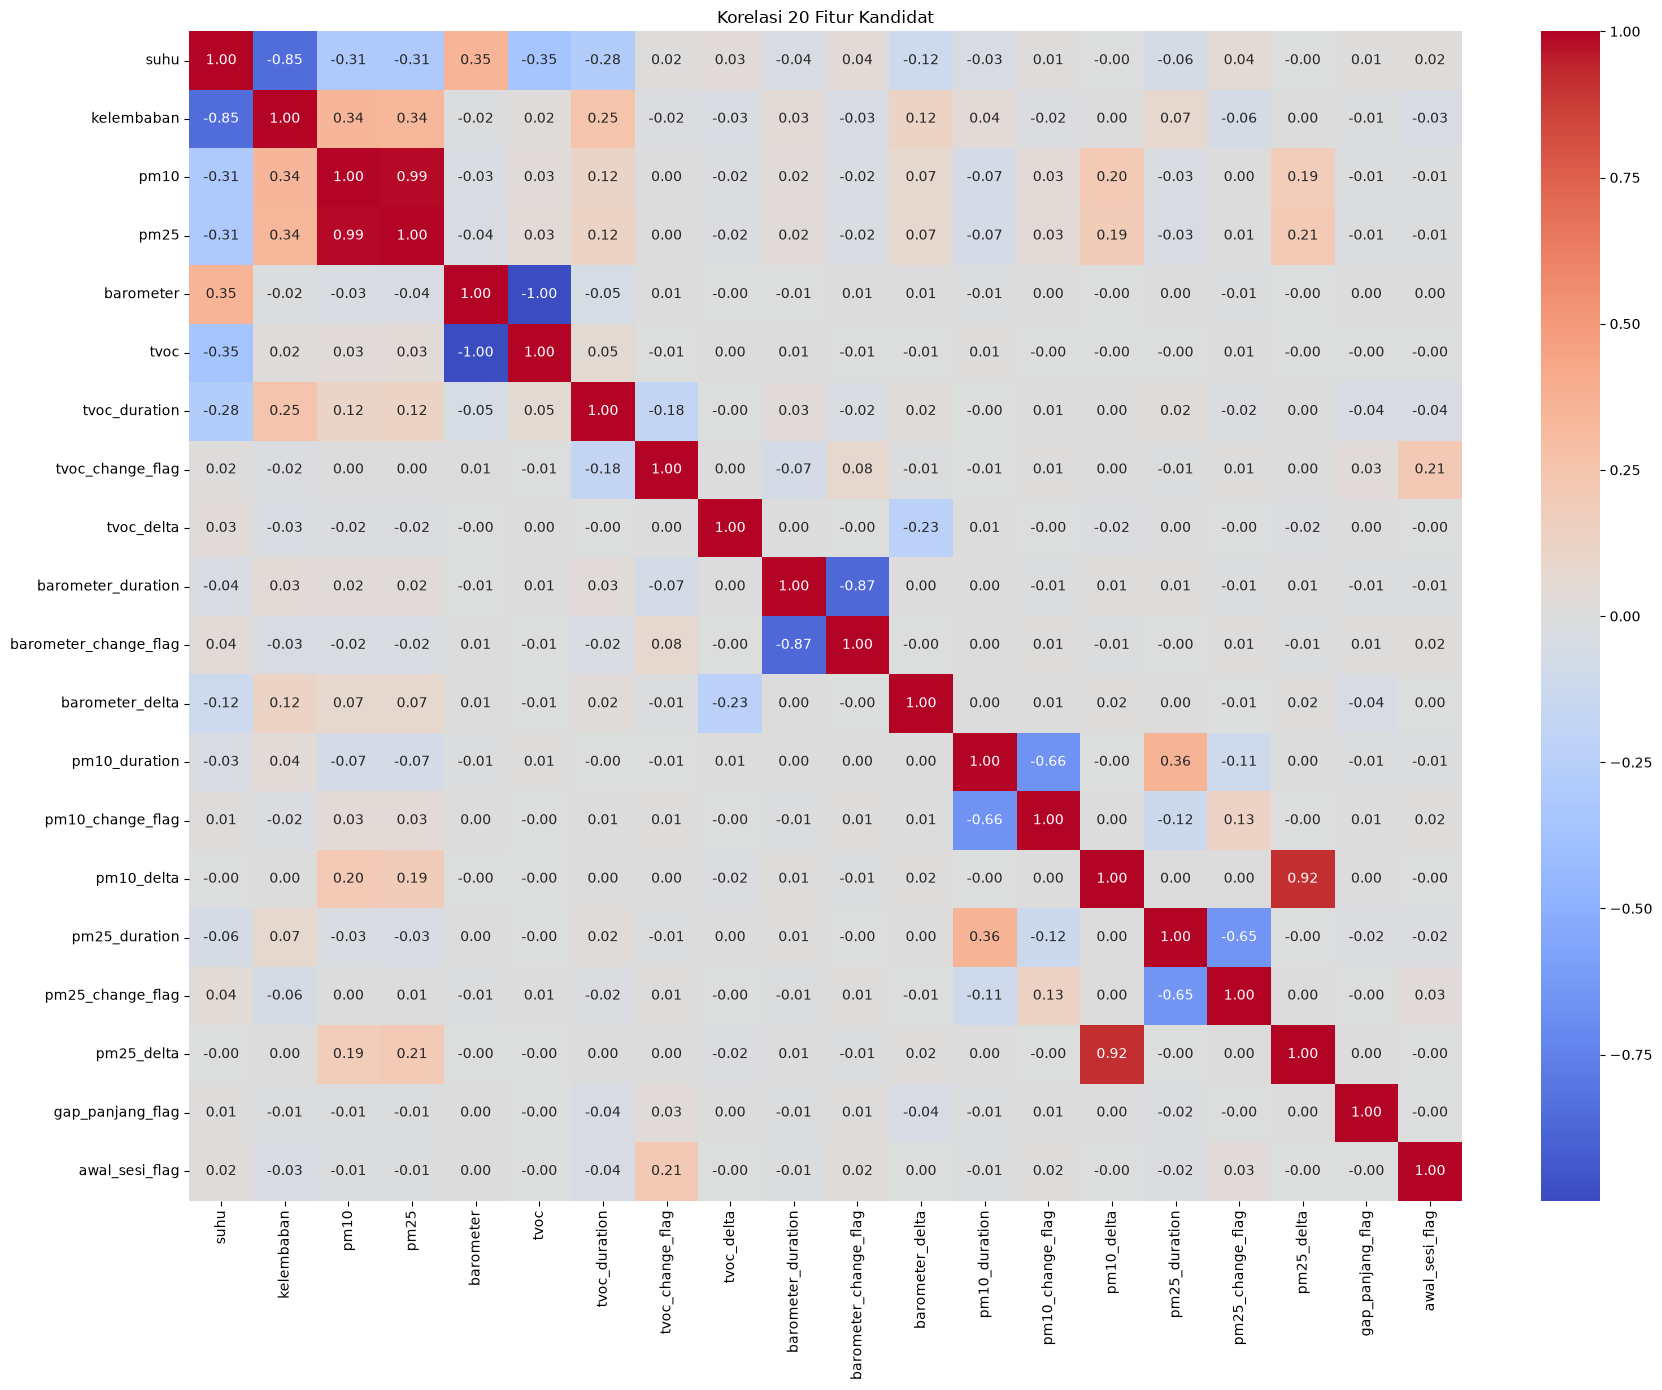

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

korelasi = df[fitur_kandidat_final].corr()

plt.figure(figsize=(18, 14))

sns.heatmap(
    korelasi,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Korelasi 20 Fitur Kandidat")
plt.tight_layout()
plt.show()

In [35]:
import numpy as np

korelasi = df[fitur_kandidat_final].corr()

mask = np.triu(
    np.ones(korelasi.shape),
    k=1
).astype(bool)

pasangan_korelasi = (
    korelasi.where(mask)
    .stack()
    .reset_index()
)

pasangan_korelasi.columns = [
    "fitur_1",
    "fitur_2",
    "korelasi"
]

pasangan_korelasi["korelasi_absolut"] = (
    pasangan_korelasi["korelasi"].abs()
)

hasil_korelasi_tinggi = (
    pasangan_korelasi[
        pasangan_korelasi["korelasi_absolut"] >= 0.80
    ]
    .sort_values(
        "korelasi_absolut",
        ascending=False
    )
)

display(hasil_korelasi_tinggi.round(3))

,fitur_1,fitur_2,korelasi,korelasi_absolut
85,barometer,tvoc,-1.000,1.000
43,pm10,pm25,0.989,0.989
297,pm10_delta,pm25_delta,0.922,0.922
190,barometer_duration,barometer_change_flag,-0.867,0.867
1,suhu,kelembaban,-0.847,0.847


In [36]:
pemetaan_fitur = {
    "Spike Anomaly": [
        "suhu", "kelembaban", "pm10", "pm25",
        "barometer", "tvoc",
        "tvoc_delta", "barometer_delta",
        "pm10_delta", "pm25_delta"
    ],

    "Stuck Value": [
        "tvoc_duration", "barometer_duration",
        "pm10_duration", "pm25_duration",
        "tvoc_change_flag", "barometer_change_flag",
        "pm10_change_flag", "pm25_change_flag"
    ],

    "Unusual Value": [
        "suhu", "kelembaban", "pm10",
        "pm25", "barometer", "tvoc"
    ],

    "Data Quality / Context": [
        "gap_panjang_flag", "awal_sesi_flag"
    ]
}

for jenis, fitur in pemetaan_fitur.items():
    print(f"\n{jenis}")
    for nama in fitur:
        print("-", nama)


Spike Anomaly
- suhu
- kelembaban
- pm10
- pm25
- barometer
- tvoc
- tvoc_delta
- barometer_delta
- pm10_delta
- pm25_delta

Stuck Value
- tvoc_duration
- barometer_duration
- pm10_duration
- pm25_duration
- tvoc_change_flag
- barometer_change_flag
- pm10_change_flag
- pm25_change_flag

Unusual Value
- suhu
- kelembaban
- pm10
- pm25
- barometer
- tvoc

Data Quality / Context
- gap_panjang_flag
- awal_sesi_flag


In [37]:
kolom_duration = [
    "tvoc_duration",
    "barometer_duration",
    "pm10_duration",
    "pm25_duration"
]

for kolom in kolom_duration:
    print(f"\n{kolom}")
    print(df[kolom].describe(
        percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
    ))


tvoc_duration
count    38531.000000
mean        66.223593
std         64.057397
min          0.000000
50%         47.283333
75%         93.025000
90%        155.083333
95%        196.300000
99%        285.696667
max        429.750000
Name: tvoc_duration, dtype: float64

barometer_duration
count    38531.000000
mean         0.251610
std          0.623799
min          0.000000
50%          0.000000
75%          0.000000
90%          1.066667
95%          1.100000
99%          3.150000
max          7.866667
Name: barometer_duration, dtype: float64

pm10_duration
count    38531.000000
mean         0.243024
std          0.864785
min          0.000000
50%          0.000000
75%          0.000000
90%          1.050000
95%          1.083333
99%          3.166667
max         30.666667
Name: pm10_duration, dtype: float64

pm25_duration
count    38531.000000
mean         0.745369
std          1.584431
min          0.000000
50%          0.000000
75%          1.050000
90%          2.166667
95%     

In [38]:
batas_durasi = [5, 10, 15]

hasil_stuck = []

for sensor in kolom_duration:
    for batas in batas_durasi:
        jumlah = (df[sensor] > batas).sum()

        hasil_stuck.append({
            "sensor": sensor,
            "batas_durasi_menit": batas,
            "jumlah_data": jumlah,
            "persentase": round(jumlah / len(df) * 100, 2)
        })

df_stuck = pd.DataFrame(hasil_stuck)

display(df_stuck)

,sensor,batas_durasi_menit,jumlah_data,persentase
0,tvoc_duration,5,34914,90.61
1,tvoc_duration,10,32535,84.44
2,tvoc_duration,15,30513,79.19
3,barometer_duration,5,31,0.08
4,barometer_duration,10,0,0.00
5,barometer_duration,15,0,0.00
6,pm10_duration,5,97,0.25
7,pm10_duration,10,35,0.09
8,pm10_duration,15,23,0.06
9,pm25_duration,5,903,2.34


In [39]:
kolom_sensor_duration = {
    "tvoc": "tvoc_duration",
    "barometer": "barometer_duration",
    "pm10": "pm10_duration",
    "pm25": "pm25_duration"
}

for sensor, kolom_durasi in kolom_sensor_duration.items():
    print(f"\nContoh {sensor.upper()} dengan durasi > 15 menit")

    contoh = df.loc[
        df[kolom_durasi] > 15,
        ["session_id", "waktu_tercatat", sensor, kolom_durasi]
    ].head(5)

    display(contoh)


Contoh TVOC dengan durasi > 15 menit


,session_id,waktu_tercatat,tvoc,tvoc_duration
14,1,2026-01-19 11:55:26,740.63,15.133333
15,1,2026-01-19 11:56:31,740.63,16.216667
16,1,2026-01-19 11:57:35,740.63,17.283333
17,1,2026-01-19 11:58:40,740.63,18.366667
18,1,2026-01-19 11:59:44,740.63,19.433333



Contoh BAROMETER dengan durasi > 15 menit


,session_id,waktu_tercatat,barometer,barometer_duration



Contoh PM10 dengan durasi > 15 menit


,session_id,waktu_tercatat,pm10,pm10_duration
2834,4,2026-02-12 21:03:42,0.0,15.300000
2835,4,2026-02-12 21:04:46,0.0,16.366667
2836,4,2026-02-12 21:05:51,0.0,17.450000
2837,4,2026-02-12 21:06:56,0.0,18.533333
2838,4,2026-02-12 21:08:00,0.0,19.600000



Contoh PM25 dengan durasi > 15 menit


,session_id,waktu_tercatat,pm25,pm25_duration
2834,4,2026-02-12 21:03:42,0.0,15.300000
2835,4,2026-02-12 21:04:46,0.0,16.366667
2836,4,2026-02-12 21:05:51,0.0,17.450000
2837,4,2026-02-12 21:06:56,0.0,18.533333
2838,4,2026-02-12 21:08:00,0.0,19.600000


In [40]:
for sensor, kolom_durasi in kolom_sensor_duration.items():

    indeks = df.index[df[kolom_durasi] > 15]

    print(f"\nPemeriksaan {sensor.upper()}")

    if len(indeks) == 0:
        print("Tidak ditemukan durasi lebih dari 15 menit.")
        continue

    posisi = df.index.get_loc(indeks[0])

    awal = max(0, posisi - 5)
    akhir = min(len(df), posisi + 10)

    kolom_tampil = [
        "session_id",
        "waktu_tercatat",
        sensor,
        kolom_durasi
    ]

    display(df.iloc[awal:akhir][kolom_tampil])


Pemeriksaan TVOC


,session_id,waktu_tercatat,tvoc,tvoc_duration
9,1,2026-01-19 11:50:02,740.63,9.733333
10,1,2026-01-19 11:51:07,740.63,10.816667
11,1,2026-01-19 11:52:11,740.63,11.883333
12,1,2026-01-19 11:53:16,740.63,12.966667
13,1,2026-01-19 11:54:21,740.63,14.050000
14,1,2026-01-19 11:55:26,740.63,15.133333
15,1,2026-01-19 11:56:31,740.63,16.216667
16,1,2026-01-19 11:57:35,740.63,17.283333
17,1,2026-01-19 11:58:40,740.63,18.366667
18,1,2026-01-19 11:59:44,740.63,19.433333



Pemeriksaan BAROMETER
Tidak ditemukan durasi lebih dari 15 menit.

Pemeriksaan PM10


,session_id,waktu_tercatat,pm10,pm10_duration
2829,4,2026-02-12 20:58:19,0.0,9.916667
2830,4,2026-02-12 20:59:23,0.0,10.983333
2831,4,2026-02-12 21:00:28,0.0,12.066667
2832,4,2026-02-12 21:01:33,0.0,13.150000
2833,4,2026-02-12 21:02:37,0.0,14.216667
2834,4,2026-02-12 21:03:42,0.0,15.300000
2835,4,2026-02-12 21:04:46,0.0,16.366667
2836,4,2026-02-12 21:05:51,0.0,17.450000
2837,4,2026-02-12 21:06:56,0.0,18.533333
2838,4,2026-02-12 21:08:00,0.0,19.600000



Pemeriksaan PM25


,session_id,waktu_tercatat,pm25,pm25_duration
2829,4,2026-02-12 20:58:19,0.0,9.916667
2830,4,2026-02-12 20:59:23,0.0,10.983333
2831,4,2026-02-12 21:00:28,0.0,12.066667
2832,4,2026-02-12 21:01:33,0.0,13.150000
2833,4,2026-02-12 21:02:37,0.0,14.216667
2834,4,2026-02-12 21:03:42,0.0,15.300000
2835,4,2026-02-12 21:04:46,0.0,16.366667
2836,4,2026-02-12 21:05:51,0.0,17.450000
2837,4,2026-02-12 21:06:56,0.0,18.533333
2838,4,2026-02-12 21:08:00,0.0,19.600000


In [41]:
for sensor, kolom_durasi in kolom_sensor_duration.items():

    kandidat = (df[kolom_durasi] > 15).to_numpy().nonzero()[0]

    print(f"\nAkhir periode berulang: {sensor.upper()}")

    if len(kandidat) == 0:
        print("Tidak ditemukan kandidat.")
        continue

    posisi = kandidat[0]
    nilai = df.iloc[posisi][sensor]
    sesi = df.iloc[posisi]["session_id"]

    akhir = posisi

    for j in range(posisi + 1, len(df)):
        baris = df.iloc[j]

        if (
            baris["session_id"] != sesi
            or baris[sensor] != nilai
            or baris["gap_sec"] > 300
        ):
            break

        akhir = j

    awal_tampil = max(0, akhir - 5)
    akhir_tampil = min(len(df), akhir + 6)

    display(df.iloc[awal_tampil:akhir_tampil][
        ["session_id", "waktu_tercatat", sensor, kolom_durasi]
    ])


Akhir periode berulang: TVOC


,session_id,waktu_tercatat,tvoc,tvoc_duration
38,1,2026-01-19 12:21:17,740.63,40.983333
39,1,2026-01-19 12:22:21,740.63,42.050000
40,1,2026-01-19 12:23:26,740.63,43.133333
41,1,2026-01-19 12:24:31,740.63,44.216667
42,1,2026-01-19 12:25:35,740.63,45.283333
43,1,2026-01-19 12:26:40,740.63,46.366667
44,1,2026-01-19 12:27:44,749.56,0.000000
45,1,2026-01-19 12:28:49,749.56,1.083333
46,1,2026-01-19 12:29:54,749.56,2.166667
47,1,2026-01-19 12:30:58,749.56,3.233333



Akhir periode berulang: BAROMETER
Tidak ditemukan kandidat.

Akhir periode berulang: PM10


,session_id,waktu_tercatat,pm10,pm10_duration
2842,4,2026-02-12 21:13:37,0.0,25.216667
2843,4,2026-02-12 21:14:45,0.0,26.350000
2844,4,2026-02-12 21:15:50,0.0,27.433333
2845,4,2026-02-12 21:16:54,0.0,28.500000
2846,4,2026-02-12 21:17:59,0.0,29.583333
2847,4,2026-02-12 21:19:04,0.0,30.666667
2848,4,2026-02-12 21:20:08,1.0,0.000000
2849,4,2026-02-12 21:21:13,1.0,1.083333
2850,4,2026-02-12 21:22:17,3.0,0.000000
2851,4,2026-02-12 21:23:22,1.0,0.000000



Akhir periode berulang: PM25


,session_id,waktu_tercatat,pm25,pm25_duration
2843,4,2026-02-12 21:14:45,0.0,26.350000
2844,4,2026-02-12 21:15:50,0.0,27.433333
2845,4,2026-02-12 21:16:54,0.0,28.500000
2846,4,2026-02-12 21:17:59,0.0,29.583333
2847,4,2026-02-12 21:19:04,0.0,30.666667
2848,4,2026-02-12 21:20:08,0.0,31.733333
2849,4,2026-02-12 21:21:13,1.0,0.000000
2850,4,2026-02-12 21:22:17,2.0,0.000000
2851,4,2026-02-12 21:23:22,0.0,0.000000
2852,4,2026-02-12 21:24:27,0.0,1.083333


In [42]:
kolom_delta = [
    "tvoc_delta",
    "barometer_delta",
    "pm10_delta",
    "pm25_delta"
]

for kolom in kolom_delta:
    print(f"\nPerubahan terbesar: {kolom}")

    display(
        df.loc[
            df[kolom].abs().nlargest(5).index,
            ["session_id", "waktu_tercatat", kolom.replace("_delta", ""), kolom]
        ].sort_values("waktu_tercatat")
    )


Perubahan terbesar: tvoc_delta


,session_id,waktu_tercatat,tvoc,tvoc_delta
23569,27,2026-06-26 14:14:28,1366.63,9.49
23573,27,2026-06-26 14:18:41,1357.14,-9.49
23575,27,2026-06-26 14:20:47,1366.63,9.49
23615,27,2026-06-26 15:02:59,1357.14,-9.49
23622,27,2026-06-26 15:10:23,1366.63,9.49



Perubahan terbesar: barometer_delta


,session_id,waktu_tercatat,barometer,barometer_delta
51,1,2026-01-19 13:30:22,699.99,-0.61
21202,24,2026-06-18 12:20:19,701.93,-0.52
21206,25,2026-06-18 13:58:40,700.73,-0.34
24866,34,2026-07-27 13:45:17,701.38,-0.52
37418,50,2026-11-12 18:27:24,752.86,0.56



Perubahan terbesar: pm10_delta


,session_id,waktu_tercatat,pm10,pm10_delta
19913,23,2026-06-15 11:08:54,353.0,304.0
19914,23,2026-06-15 11:09:57,36.0,-317.0
20028,23,2026-06-15 13:17:41,489.0,470.0
20029,23,2026-06-15 13:18:44,35.0,-454.0
25734,40,2026-08-29 01:32:46,224.0,165.0



Perubahan terbesar: pm25_delta


,session_id,waktu_tercatat,pm25,pm25_delta
19913,23,2026-06-15 11:08:54,174.0,151.0
19914,23,2026-06-15 11:09:57,17.0,-157.0
20028,23,2026-06-15 13:17:41,221.0,211.0
20029,23,2026-06-15 13:18:44,17.0,-204.0
25734,40,2026-08-29 01:32:46,112.0,85.0


In [3]:
indeks_spike = [19913, 19914, 20028, 20029]

kolom_tampil = [
    "session_id",
    "waktu_tercatat",
    "suhu",
    "kelembaban",
    "pm10",
    "pm10_delta",
    "pm25",
    "pm25_delta"
]

for indeks in indeks_spike:
    print(f"\nPemeriksaan sekitar indeks {indeks}")

    display(
        df.loc[
            max(0, indeks - 3):min(len(df) - 1, indeks + 3),
            kolom_tampil
        ]
    )


Pemeriksaan sekitar indeks 19913


KeyError: "['session_id', 'pm10_delta', 'pm25_delta'] not in index"

In [2]:
import pandas as pd

df = pd.read_csv(
    r"C:\AI-Anomaly-Detection\dataset\DATA SENSOR.csv"
)

print("Dataset berhasil dimuat!")
print("Jumlah baris:", len(df))
print("Jumlah kolom:", len(df))

Dataset berhasil dimuat!
Jumlah baris: 38531
Jumlah kolom: 38531


In [4]:
print("Jumlah kolom:", len(df.columns))

for kolom in df.columns:
    print(repr(kolom))

Jumlah kolom: 8
'id_monitoring_udara'
'suhu'
'kelembaban'
'pm10'
'pm25'
'barometer'
'tvoc'
'waktu_tercatat'


In [5]:
display(df.head())

,id_monitoring_udara,suhu,kelembaban,pm10,pm25,barometer,tvoc,waktu_tercatat
0,164460,29.39,46,8.0,3.0,701.29,740.63,2026-01-19 11:40:18
1,164461,29.29,46,5.0,2.0,701.27,740.63,2026-01-19 11:41:22
2,164462,29.39,45,1.0,0.0,701.26,740.63,2026-01-19 11:42:27
3,164463,29.39,45,4.0,1.0,701.26,740.63,2026-01-19 11:43:31
4,164464,29.29,44,0.0,0.0,701.27,740.63,2026-01-19 11:44:36
